# Análise exploratória de um e-commerce brasileiro (Olist)

**Autora:** Thaís Miranda Lopes

Este notebook analisa cerca de 100 mil pedidos reais do marketplace Olist, feitos entre 2016 e 2018.

Olhei a base com a cabeça de quem trabalha com CRM. Quis responder cinco perguntas de negócio:

1. Como as vendas evoluíram mês a mês?
2. Quantos clientes voltam a comprar?
3. Em que dia e horário os clientes mais compram?
4. O atraso na entrega afeta a nota que o cliente dá?
5. Quais categorias concentram a receita?

**Ferramentas:** Python, Pandas e Matplotlib.

## 1. Preparação

Carrego as bibliotecas e as cinco tabelas que vou usar.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

PASTA_DADOS = "../dados/"
PASTA_IMAGENS = "../imagens/"

pedidos = pd.read_csv(PASTA_DADOS + "olist_orders_dataset.csv")
itens = pd.read_csv(PASTA_DADOS + "olist_order_items_dataset.csv")
clientes = pd.read_csv(PASTA_DADOS + "olist_customers_dataset.csv")
avaliacoes = pd.read_csv(PASTA_DADOS + "olist_order_reviews_dataset.csv")
produtos = pd.read_csv(PASTA_DADOS + "olist_products_dataset.csv")

tabelas = {
    "pedidos": pedidos,
    "itens": itens,
    "clientes": clientes,
    "avaliacoes": avaliacoes,
    "produtos": produtos,
}

for nome, tabela in tabelas.items():
    print(f"{nome}: {tabela.shape[0]} linhas e {tabela.shape[1]} colunas")

pedidos: 99441 linhas e 8 colunas
itens: 112650 linhas e 7 colunas
clientes: 99441 linhas e 5 colunas
avaliacoes: 99224 linhas e 7 colunas
produtos: 32951 linhas e 9 colunas


In [2]:
# Duas funções pequenas para não repetir código nos gráficos.

CINZA = "#BDBDBD"
PRETO = "#212121"


def formato_br(numero, casas=0):
    # Escreve o número no padrão brasileiro: 1.234,56
    texto = f"{numero:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def limpar_grafico(eixo, titulo):
    # Tira as bordas de cima e da direita e coloca o título à esquerda.
    eixo.spines["top"].set_visible(False)
    eixo.spines["right"].set_visible(False)
    eixo.set_title(titulo, loc="left", fontsize=13, fontweight="bold")

## 2. Conhecendo e tratando os dados

Antes de analisar, preciso saber se a base está confiável. Verifico três coisas: campos vazios, linhas duplicadas e tipos de dado errados.

In [3]:
pedidos.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
# Quantos campos vazios existem em cada tabela?
for nome, tabela in tabelas.items():
    vazios = tabela.isna().sum()
    vazios = vazios[vazios > 0]
    print(f"--- {nome} ---")
    if len(vazios) == 0:
        print("sem campos vazios")
    else:
        print(vazios.to_string())
    print(f"linhas duplicadas: {tabela.duplicated().sum()}")
    print()

--- pedidos ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
linhas duplicadas: 0

--- itens ---
sem campos vazios


linhas duplicadas: 0

--- clientes ---
sem campos vazios


linhas duplicadas: 0

--- avaliacoes ---
review_comment_title      87656
review_comment_message    58247
linhas duplicadas: 0

--- produtos ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
linhas duplicadas: 0



**O que encontrei:**

- Em `pedidos`, as datas de entrega vazias são de pedidos que ainda não tinham sido entregues. Não é erro.
- Em `avaliacoes`, os vazios são comentários que o cliente não escreveu. A nota existe.
- Em `produtos`, 610 produtos estão sem categoria. Trato isso na pergunta 5.
- Nenhuma tabela tem linha duplicada.

In [5]:
# As datas chegam como texto. Converto para data de verdade.
colunas_de_data = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for coluna in colunas_de_data:
    pedidos[coluna] = pd.to_datetime(pedidos[coluna])

print("Primeiro pedido:", pedidos["order_purchase_timestamp"].min())
print("Último pedido:  ", pedidos["order_purchase_timestamp"].max())

Primeiro pedido: 2016-09-04 21:15:19
Último pedido:   2018-10-17 17:30:18


In [6]:
# Qual é a situação dos pedidos?
pedidos["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

**Decisão 1.** Uso só os pedidos com status `delivered` (entregue). Pedido cancelado ou parado no meio do caminho não é venda concluída.

In [7]:
entregues = pedidos[pedidos["order_status"] == "delivered"].copy()

percentual = len(entregues) / len(pedidos) * 100
print(f"Pedidos entregues: {len(entregues)} ({percentual:.1f}% do total)")

Pedidos entregues: 96478 (97.0% do total)


In [8]:
# A tabela de itens tem uma linha por produto dentro do pedido.
# Somo o preço e o frete para ter uma linha por pedido.
valor_por_pedido = itens.groupby("order_id").agg(
    valor=("price", "sum"),
    frete=("freight_value", "sum"),
).reset_index()

# Junto o valor e os dados do cliente na tabela de pedidos entregues.
entregues = entregues.merge(valor_por_pedido, on="order_id", how="left")
entregues = entregues.merge(clientes, on="customer_id", how="left")

print("Pedidos sem valor depois da junção:", entregues["valor"].isna().sum())
print("Linhas depois da junção:", len(entregues))

Pedidos sem valor depois da junção: 0
Linhas depois da junção: 96478


A junção não perdeu nem duplicou pedidos. A base está pronta.

### Números gerais

In [9]:
receita_total = entregues["valor"].sum()
ticket_medio = entregues["valor"].mean()
ticket_mediano = entregues["valor"].median()

print("Receita em produtos: R$", formato_br(receita_total, 2))
print("Ticket médio:        R$", formato_br(ticket_medio, 2))
print("Ticket mediano:      R$", formato_br(ticket_mediano, 2))

Receita em produtos: R$ 13.221.498,11
Ticket médio:        R$ 137,04
Ticket mediano:      R$ 86,57


O ticket médio (R$ 137) é bem maior que o mediano (R$ 87). Isso mostra que poucos pedidos muito caros puxam a média para cima. **Metade dos pedidos vale até R$ 87.**

## 3. Como as vendas evoluíram mês a mês?

In [10]:
entregues["mes"] = entregues["order_purchase_timestamp"].dt.to_period("M")
entregues.groupby("mes").size()

mes
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, dtype: int64

**Decisão 2.** Os meses de 2016 e os de setembro e outubro de 2018 têm pouquíssimos pedidos. São as pontas da extração, não meses reais de venda. Para a evolução mensal, uso de janeiro de 2017 a agosto de 2018.

In [11]:
periodo = entregues[(entregues["mes"] >= "2017-01") & (entregues["mes"] <= "2018-08")]

pedidos_por_mes = periodo.groupby("mes").size()
pedidos_por_mes.index = pedidos_por_mes.index.astype(str)

mes_pico = pedidos_por_mes.idxmax()
print("Mês com mais pedidos:", mes_pico, "com", pedidos_por_mes.max(), "pedidos")

Mês com mais pedidos: 2017-11 com 7289 pedidos


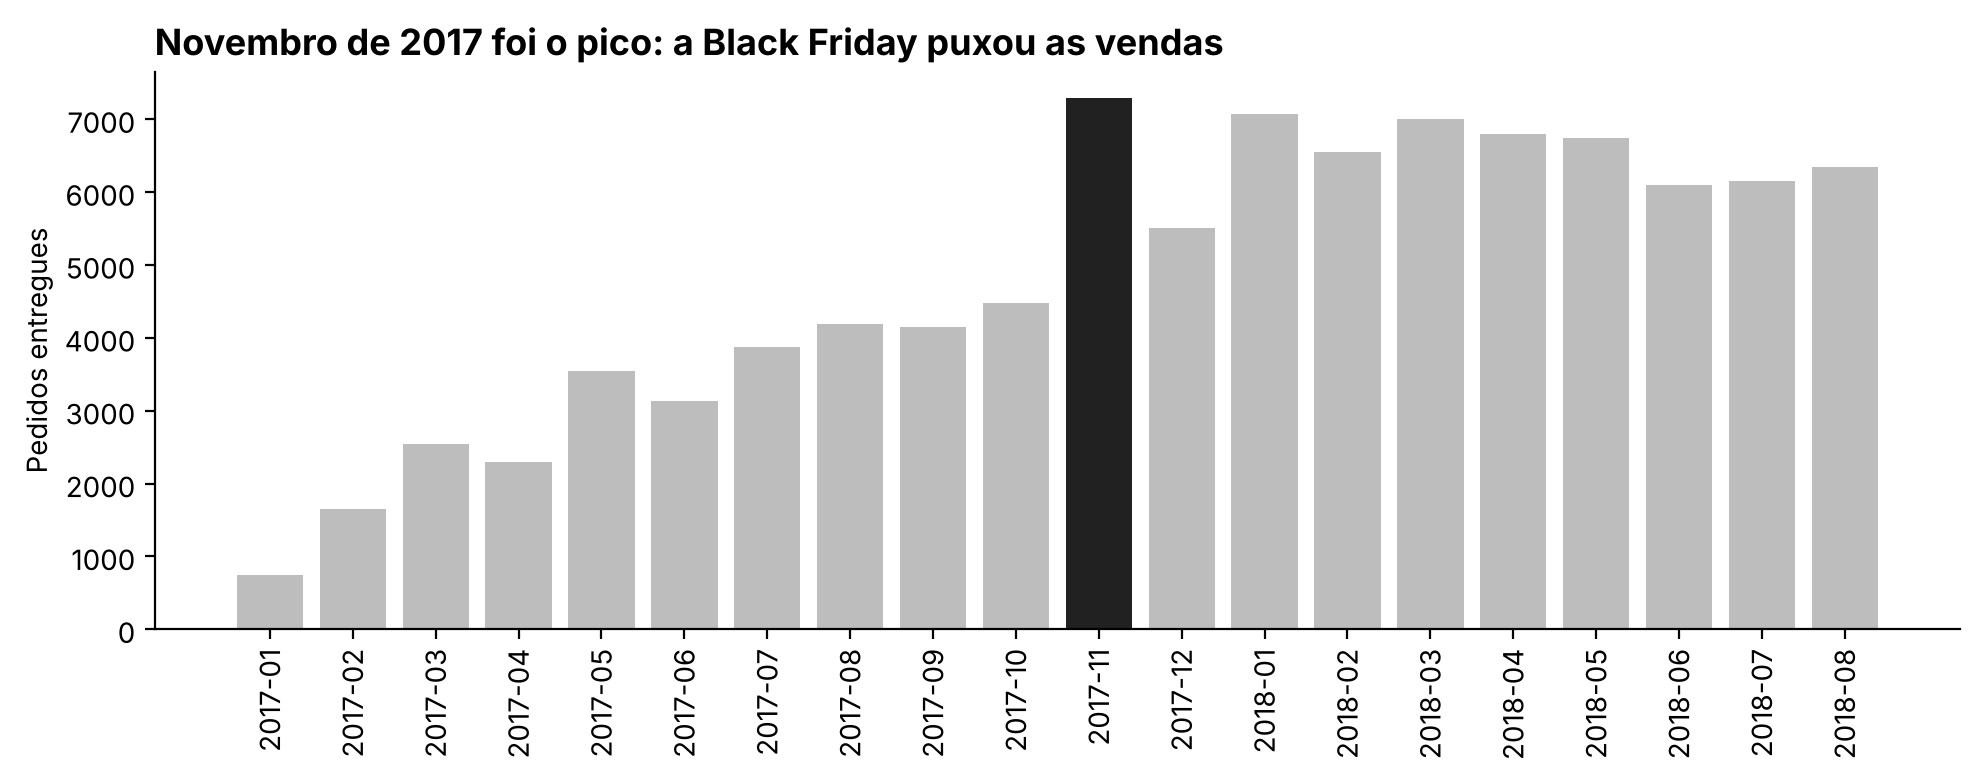

In [12]:
cores = [PRETO if mes == mes_pico else CINZA for mes in pedidos_por_mes.index]

figura, eixo = plt.subplots(figsize=(10, 4))
eixo.bar(pedidos_por_mes.index, pedidos_por_mes.values, color=cores)
limpar_grafico(eixo, "Novembro de 2017 foi o pico: a Black Friday puxou as vendas")
eixo.set_ylabel("Pedidos entregues")
eixo.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS + "01_pedidos_por_mes.png", dpi=150)
plt.show()

**Leitura:** as vendas cresceram durante todo 2017. Novembro de 2017 foi o pico, com 7.289 pedidos, 63% acima de outubro. Depois da Black Friday, 2018 se manteve em um novo patamar, entre 6 e 7 mil pedidos por mês.

## 4. Quantos clientes voltam a comprar?

Atenção a um detalhe da base: o `customer_id` muda a cada pedido. Quem identifica a pessoa de verdade é o `customer_unique_id`. Se eu usasse o campo errado, a recompra daria zero.

In [13]:
pedidos_por_cliente = entregues.groupby("customer_unique_id")["order_id"].count()

total_clientes = len(pedidos_por_cliente)
clientes_recompra = (pedidos_por_cliente > 1).sum()
taxa_recompra = clientes_recompra / total_clientes * 100

print("Clientes únicos:", total_clientes)
print("Compraram mais de uma vez:", clientes_recompra)
print(f"Taxa de recompra: {taxa_recompra:.1f}%")

Clientes únicos: 93358
Compraram mais de uma vez: 2801
Taxa de recompra: 3.0%


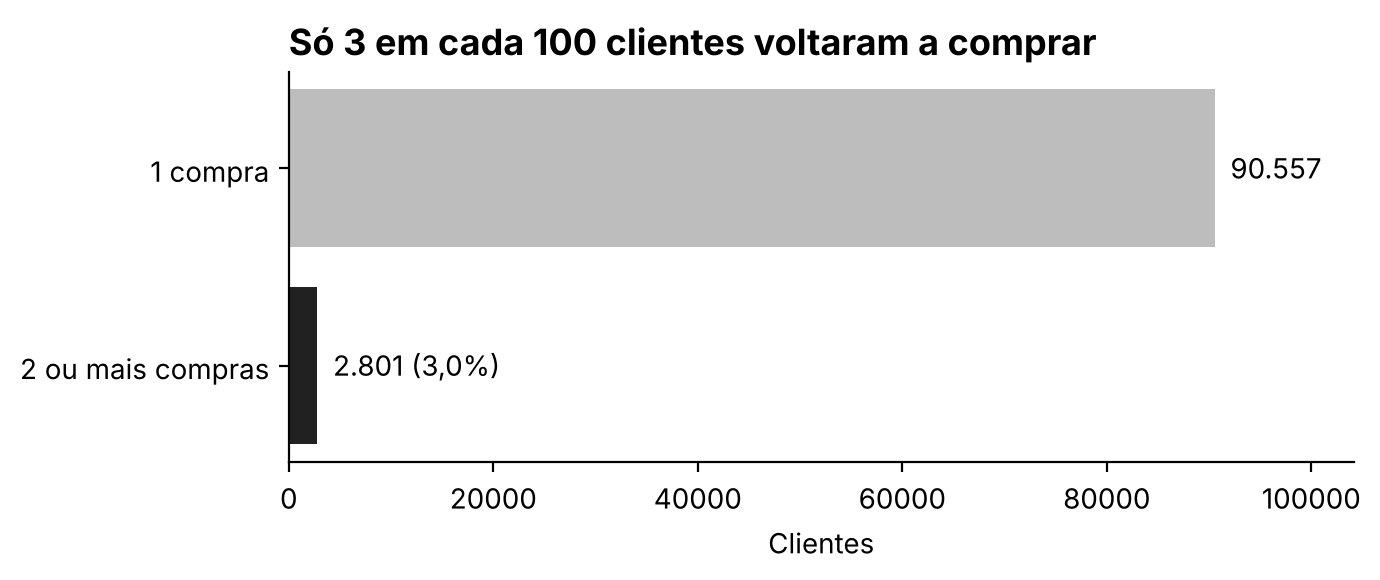

In [14]:
uma_compra = total_clientes - clientes_recompra

figura, eixo = plt.subplots(figsize=(7, 3))
eixo.barh(["2 ou mais compras", "1 compra"], [clientes_recompra, uma_compra], color=[PRETO, CINZA])
limpar_grafico(eixo, "Só 3 em cada 100 clientes voltaram a comprar")
eixo.set_xlabel("Clientes")
eixo.text(clientes_recompra, 0, f"  {formato_br(clientes_recompra)} ({formato_br(taxa_recompra, 1)}%)", va="center")
eixo.text(uma_compra, 1, f"  {formato_br(uma_compra)}", va="center")
eixo.set_xlim(0, uma_compra * 1.15)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS + "02_recompra.png", dpi=150)
plt.show()

**Leitura:** 97% dos clientes compraram uma única vez. Este é o maior achado da análise.

O negócio depende quase todo de cliente novo, que é o mais caro de conquistar. Uma régua de pós-compra (segunda compra, reativação, recomendação por categoria) é a alavanca mais óbvia aqui.

**Limite da análise:** a base cobre só dois anos e é uma amostra. Parte desses clientes pode ter voltado depois.

## 5. Em que dia e horário os clientes mais compram?

In [15]:
nomes_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

# dayofweek devolve 0 para segunda e 6 para domingo.
pedidos_por_dia = entregues["order_purchase_timestamp"].dt.dayofweek.value_counts().sort_index()
pedidos_por_dia.index = nomes_dias
print(pedidos_por_dia.to_string())

Seg    15701
Ter    15503
Qua    15076
Qui    14323
Sex    13685
Sáb    10555
Dom    11635


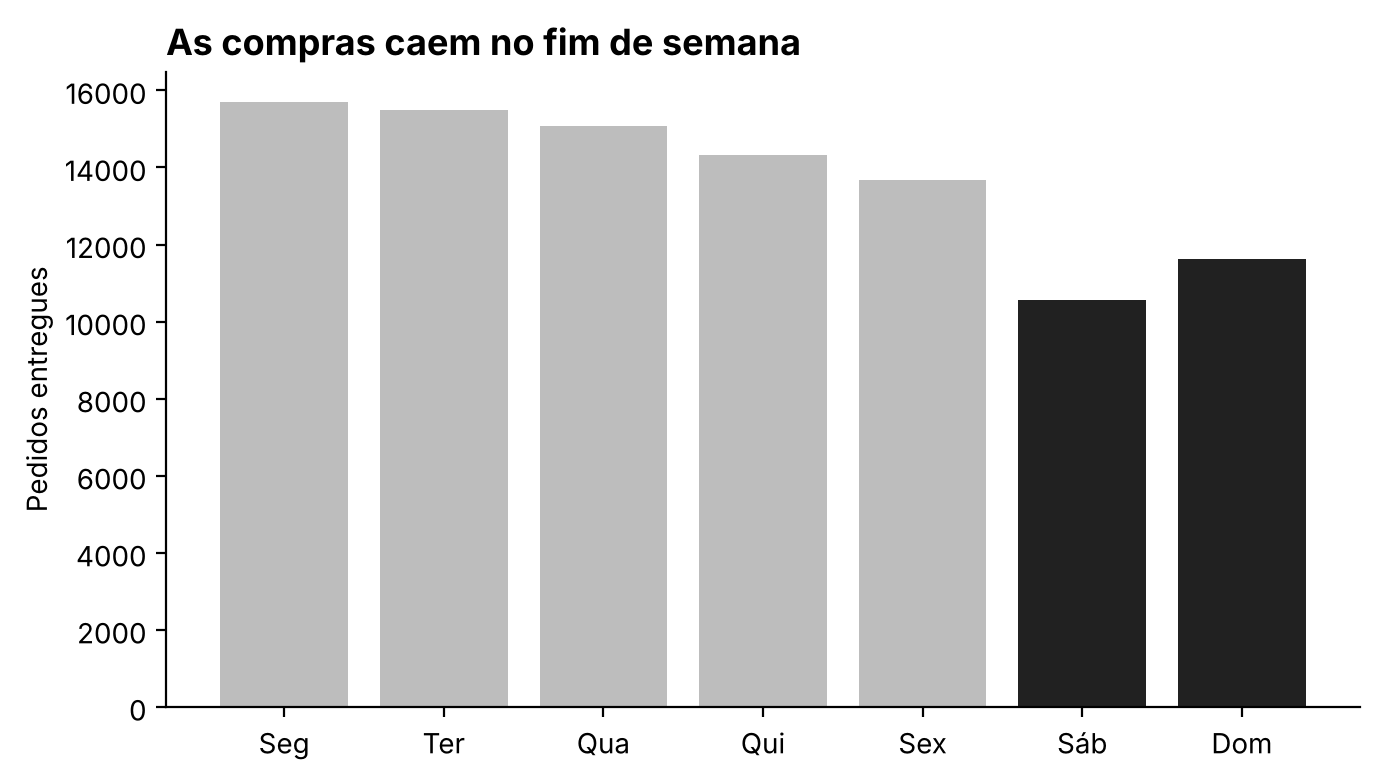

In [16]:
cores = [PRETO if dia in ["Sáb", "Dom"] else CINZA for dia in pedidos_por_dia.index]

figura, eixo = plt.subplots(figsize=(7, 4))
eixo.bar(pedidos_por_dia.index, pedidos_por_dia.values, color=cores)
limpar_grafico(eixo, "As compras caem no fim de semana")
eixo.set_ylabel("Pedidos entregues")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS + "03_pedidos_por_dia.png", dpi=150)
plt.show()

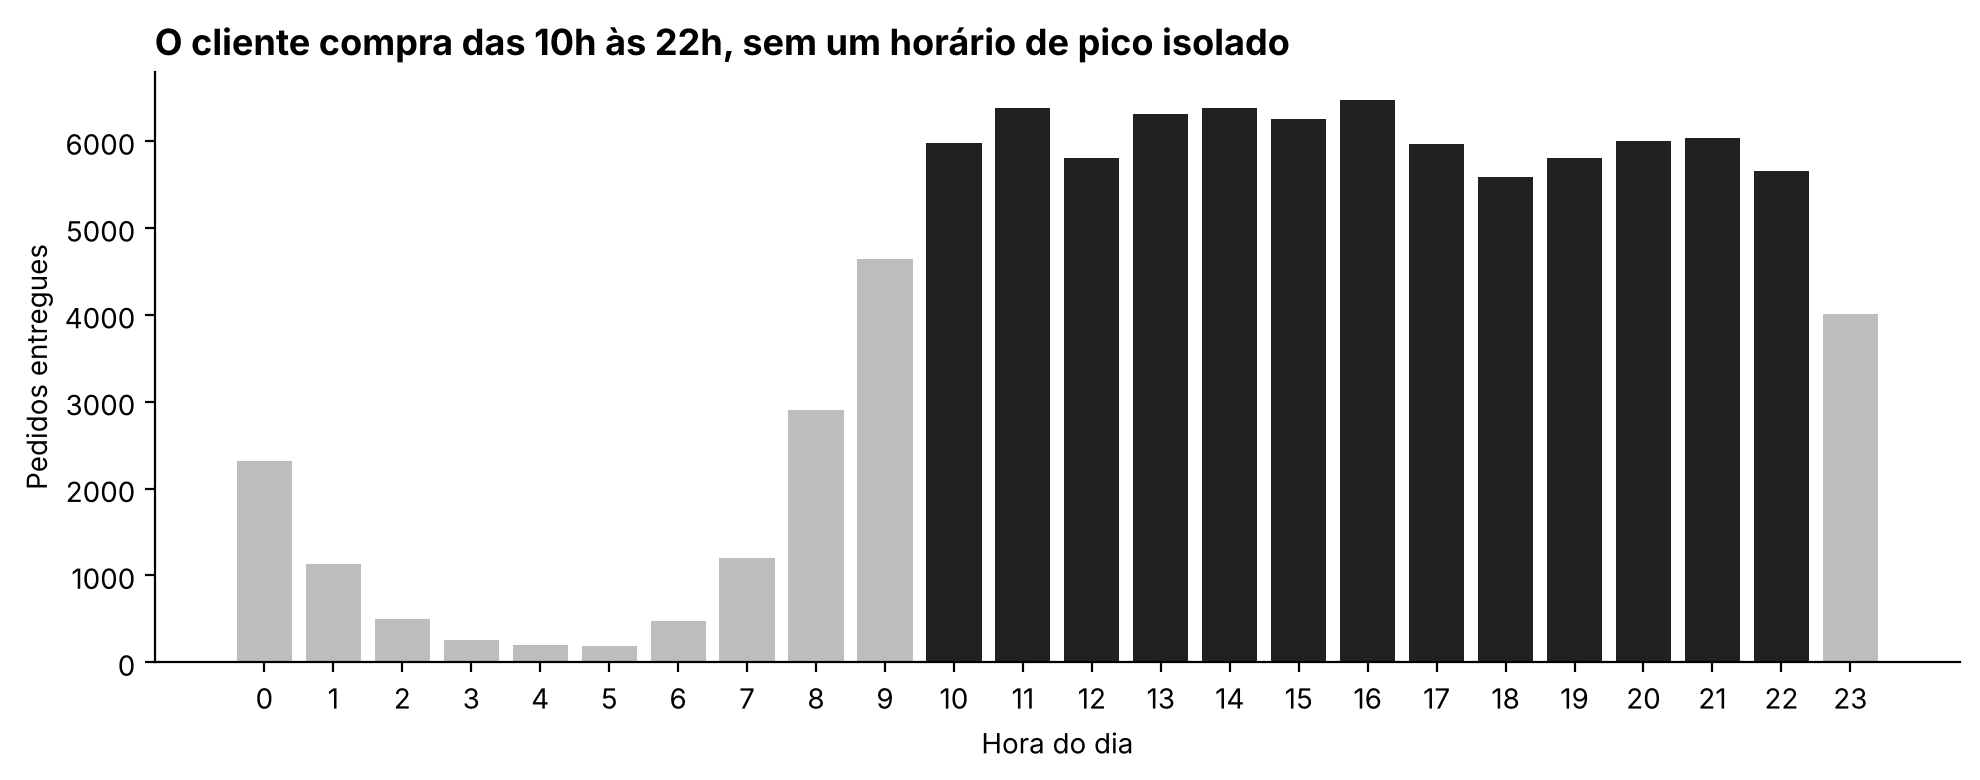

Pedidos feitos entre 10h e 22h: 81.5%


In [17]:
pedidos_por_hora = entregues["order_purchase_timestamp"].dt.hour.value_counts().sort_index()

cores = [PRETO if 10 <= hora <= 22 else CINZA for hora in pedidos_por_hora.index]

figura, eixo = plt.subplots(figsize=(10, 4))
eixo.bar(pedidos_por_hora.index, pedidos_por_hora.values, color=cores)
limpar_grafico(eixo, "O cliente compra das 10h às 22h, sem um horário de pico isolado")
eixo.set_xlabel("Hora do dia")
eixo.set_ylabel("Pedidos entregues")
eixo.set_xticks(range(0, 24))
plt.tight_layout()
plt.savefig(PASTA_IMAGENS + "04_pedidos_por_hora.png", dpi=150)
plt.show()

fatia = pedidos_por_hora.loc[10:22].sum() / pedidos_por_hora.sum() * 100
print(f"Pedidos feitos entre 10h e 22h: {fatia:.1f}%")

**Leitura:** segunda e terça são os dias mais fortes. Sábado é o mais fraco, com 33% menos pedidos que a segunda. Durante o dia, as compras se espalham das 10h às 22h, com 81,5% dos pedidos nessa janela.

Para CRM, isso indica que o começo da semana é o melhor momento para comunicações de venda. Vale confirmar com teste A/B de dia e horário de disparo, porque esta base mostra quando o cliente compra, não quando ele abre a mensagem.

## 6. O atraso na entrega afeta a nota do cliente?

In [18]:
# Dias entre a compra e a entrega.
entregues["dias_entrega"] = (
    entregues["order_delivered_customer_date"] - entregues["order_purchase_timestamp"]
).dt.days

# Atrasou se a data da entrega passou do dia prometido.
entregues["atrasou"] = (
    entregues["order_delivered_customer_date"].dt.normalize()
    > entregues["order_estimated_delivery_date"]
)

print(f"Prazo médio de entrega: {entregues['dias_entrega'].mean():.1f} dias")
print(f"Prazo mediano de entrega: {entregues['dias_entrega'].median():.0f} dias")
print(f"Pedidos entregues com atraso: {entregues['atrasou'].mean() * 100:.1f}%")

Prazo médio de entrega: 12.1 dias
Prazo mediano de entrega: 10 dias
Pedidos entregues com atraso: 6.8%


In [19]:
# Alguns pedidos têm mais de uma avaliação. Fico com a mais recente de cada pedido.
print("Pedidos com mais de uma avaliação:", avaliacoes["order_id"].duplicated().sum())

avaliacoes["review_answer_timestamp"] = pd.to_datetime(avaliacoes["review_answer_timestamp"])
avaliacao_final = avaliacoes.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")

entregues = entregues.merge(avaliacao_final[["order_id", "review_score"]], on="order_id", how="left")

print("Linhas depois da junção:", len(entregues))
print("Pedidos sem avaliação:", entregues["review_score"].isna().sum())
print(f"Nota média geral: {entregues['review_score'].mean():.2f}")

Pedidos com mais de uma avaliação: 551
Linhas depois da junção: 96478
Pedidos sem avaliação: 646
Nota média geral: 4.16


In [20]:
nota_por_atraso = entregues.groupby("atrasou")["review_score"].agg(["mean", "count"])
nota_por_atraso.index = ["No prazo", "Com atraso"]
nota_por_atraso.columns = ["nota_media", "pedidos"]
nota_por_atraso.round(2)

,nota_media,pedidos
No prazo,4.29,89451
Com atraso,2.27,6381


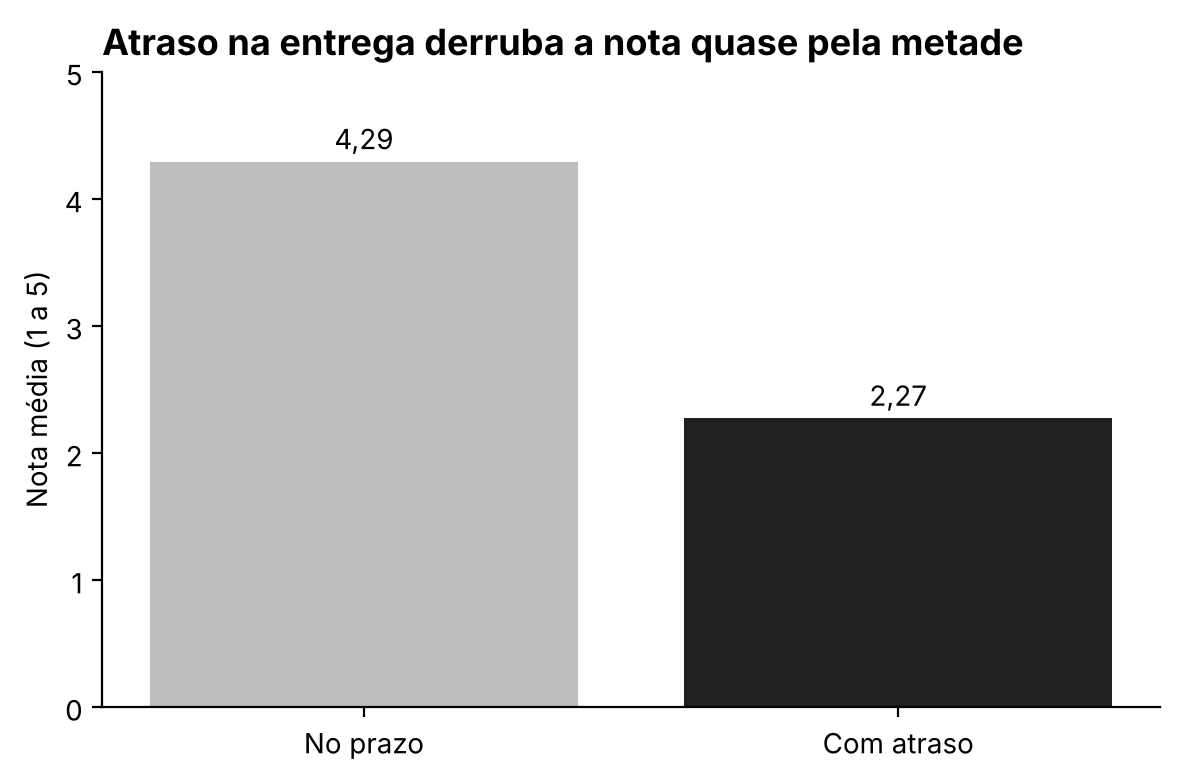

In [21]:
figura, eixo = plt.subplots(figsize=(6, 4))
eixo.bar(nota_por_atraso.index, nota_por_atraso["nota_media"], color=[CINZA, PRETO])
limpar_grafico(eixo, "Atraso na entrega derruba a nota quase pela metade")
eixo.set_ylabel("Nota média (1 a 5)")
eixo.set_ylim(0, 5)
for posicao, nota in enumerate(nota_por_atraso["nota_media"]):
    eixo.text(posicao, nota + 0.1, formato_br(nota, 2), ha="center")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS + "05_nota_por_atraso.png", dpi=150)
plt.show()

In [22]:
# A nota também cai conforme a entrega demora mais?
faixas = [-1, 7, 14, 21, 28, 1000]
nomes_faixas = ["até 7 dias", "8 a 14", "15 a 21", "22 a 28", "29 ou mais"]
entregues["faixa_entrega"] = pd.cut(entregues["dias_entrega"], bins=faixas, labels=nomes_faixas)

nota_por_faixa = entregues.groupby("faixa_entrega", observed=True)["review_score"].agg(["mean", "count"])
nota_por_faixa.columns = ["nota_media", "pedidos"]
nota_por_faixa.round(2)

,nota_media,pedidos
faixa_entrega,,
até 7 dias,4.41,33539
8 a 14,4.29,36190
15 a 21,4.10,15264
22 a 28,3.56,5933
29 ou mais,2.33,4898


**Leitura:** pedido entregue no prazo recebe nota média 4,29. Pedido atrasado recebe 2,27. A nota também cai conforme a entrega demora: de 4,41 em até 7 dias para 2,33 acima de 28 dias.

Só 6,8% dos pedidos atrasam, mas eles viram os piores detratores. Uma comunicação proativa quando o pedido vai atrasar (aviso e novo prazo) é uma ação de CRM barata para testar.

**Limite da análise:** isso é uma associação. Os dados mostram que atraso e nota baixa andam juntos, mas não provam sozinhos que um causa o outro.

## 7. Quais categorias concentram a receita?

In [23]:
# Fico só com os itens dos pedidos entregues e busco a categoria de cada produto.
itens_entregues = itens[itens["order_id"].isin(entregues["order_id"])]
itens_entregues = itens_entregues.merge(
    produtos[["product_id", "product_category_name"]], on="product_id", how="left"
)

sem_categoria = itens_entregues["product_category_name"].isna().sum()
print("Itens sem categoria:", sem_categoria, f"({sem_categoria / len(itens_entregues) * 100:.1f}% dos itens)")

# Em vez de apagar esses itens, dou um nome para eles. Assim a receita total não muda.
itens_entregues["product_category_name"] = itens_entregues["product_category_name"].fillna("sem_categoria")

receita_categoria = itens_entregues.groupby("product_category_name")["price"].sum().sort_values(ascending=False)
top10 = receita_categoria.head(10)
fatia_top10 = top10.sum() / receita_categoria.sum() * 100

print("Total de categorias:", len(receita_categoria))
print(f"Fatia das 10 maiores na receita: {fatia_top10:.1f}%")

Itens sem categoria: 1537 (1.4% dos itens)
Total de categorias: 74
Fatia das 10 maiores na receita: 62.4%


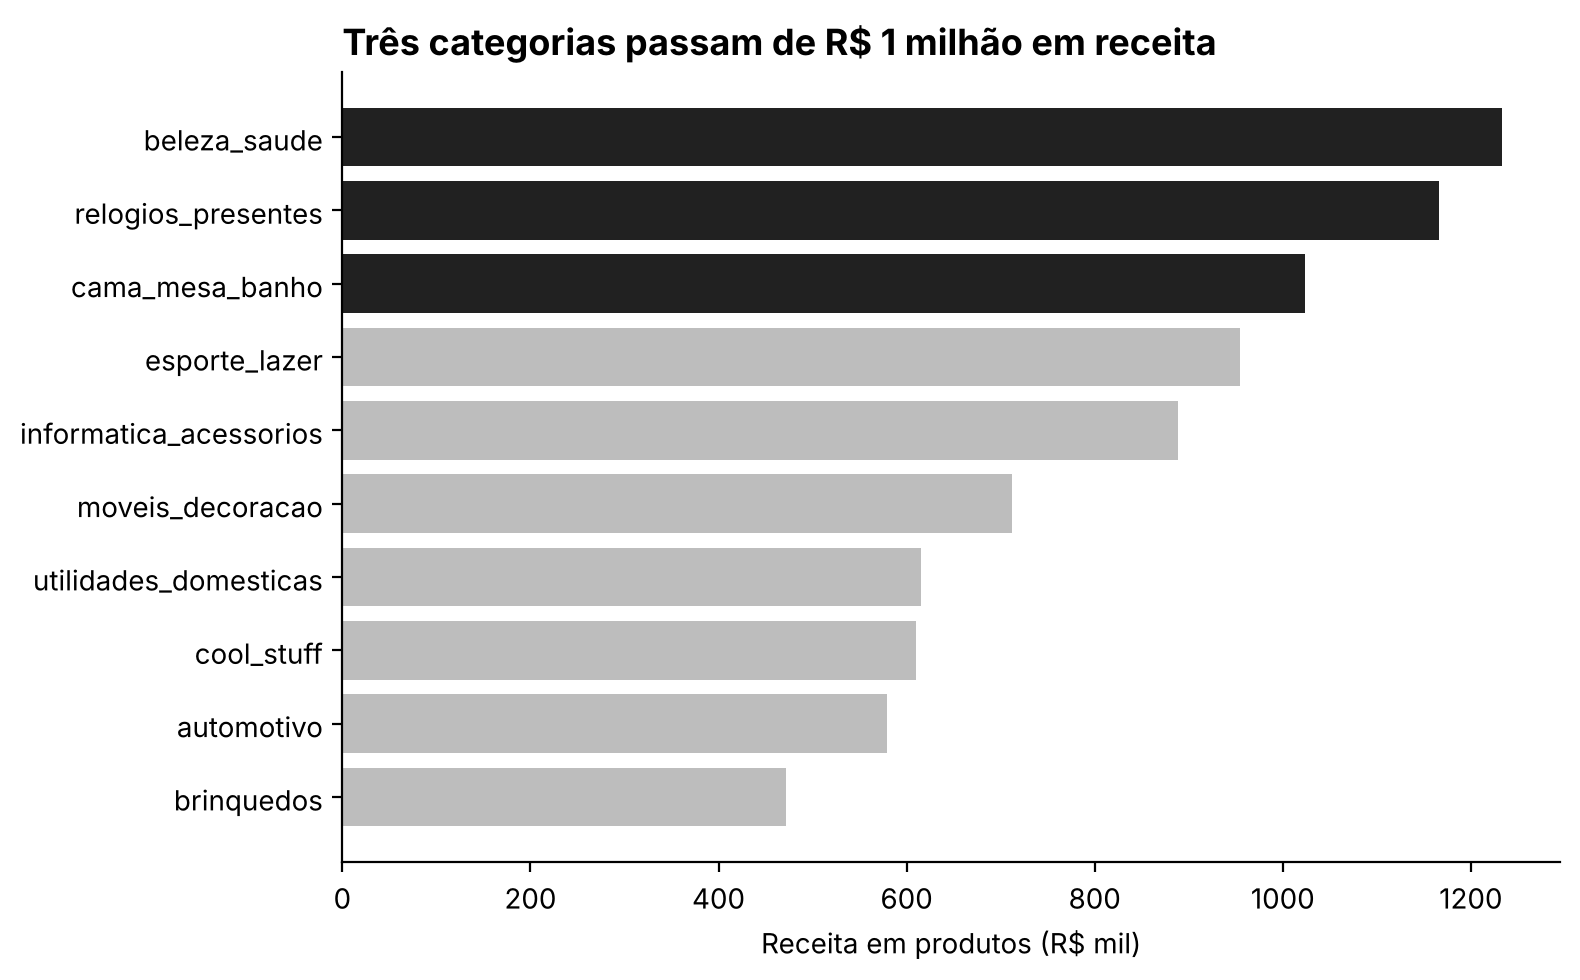

In [24]:
top10_grafico = top10.sort_values()
cores = [PRETO if posicao >= 7 else CINZA for posicao in range(10)]

figura, eixo = plt.subplots(figsize=(8, 5))
eixo.barh(top10_grafico.index, top10_grafico.values / 1000, color=cores)
limpar_grafico(eixo, "Três categorias passam de R$ 1 milhão em receita")
eixo.set_xlabel("Receita em produtos (R$ mil)")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS + "06_top_categorias.png", dpi=150)
plt.show()

**Leitura:** as 10 maiores categorias, de um total de 74 (contando o grupo sem categoria), somam 62% da receita. Beleza e saúde, relógios e presentes, e cama, mesa e banho passam de R$ 1 milhão cada.

Para CRM, são as categorias onde faz mais sentido começar réguas de recompra e de venda cruzada.

## 8. Conclusões

| Pergunta | Resposta |
|---|---|
| Evolução das vendas | Crescimento forte em 2017, pico na Black Friday (7.289 pedidos em nov/2017) e patamar de 6 a 7 mil pedidos por mês em 2018 |
| Recompra | Só 3,0% dos clientes compraram mais de uma vez |
| Dia e horário | Segunda e terça são os dias mais fortes. 81,5% dos pedidos acontecem entre 10h e 22h |
| Atraso e nota | Nota média de 4,29 no prazo contra 2,27 com atraso |
| Categorias | 10 categorias concentram 62% da receita |

### Recomendações

1. **Atacar a recompra primeiro.** Com 97% de clientes de compra única, uma régua de segunda compra tem o maior potencial de retorno.
2. **Avisar o cliente antes do atraso.** O atraso é raro (6,8%), mas derruba a nota. Comunicação proativa é barata de testar.
3. **Concentrar testes no começo da semana**, quando o cliente já compra mais.

### Próximos passos

- Segmentar os clientes por RFM (recência, frequência e valor) usando SQL.
- Criar um modelo que estime a chance de recompra de cada cliente.